<div style="background:#0f6e73;color:white;padding:28px 32px;border-radius:10px;border-bottom:6px solid #8cc63f">
<h1 style="margin:0;color:white">Conciliação de faturas: Enel × cobranças Goener</h1>
<p style="margin:6px 0 0;font-size:16px">Case técnico · Analista de Tecnologias e Operações · Viviane Pereira</p>
</div>

### O problema em uma frase
A Goener cobra os clientes pela energia solar que aparece como **energia compensada** na conta da Enel. Alguns boletos não batem com a fatura. Este notebook descobre **onde está o erro, quanto custa e como impedir que se repita**.

### Regra de negócio
> **valor da cobrança = energia compensada (kWh) × tarifa (R$/kWh) × (1 − desconto contratado)**, arredondado em 2 casas.

### Roteiro
| Etapa | O que responde |
|---|---|
| **1. Tratamento e qualidade dos dados** | Os dados são confiáveis? O que estava errado e o que foi feito? |
| **2. Conciliação** | Cada boleto está certo, a maior, a menor, faltando ou indevido? |
| **3. Indicadores** | Quanto isso custa e como evolui mês a mês? |
| **4. Prevenção** | Como impedir que os erros voltem? |
| Diferenciais | SQL, Power BI e Microsoft Fabric |
| **Resumo executivo** | O que a gestão precisa saber e fazer. |

**Organização do código:** a lógica fica em funções no pasta `src/` (reutilizáveis e testáveis). O notebook só chama as funções e mostra os resultados.

## Preparação

### Bibliotecas utilizadas
| Biblioteca | Versão | Uso |
|---|---|---|
| **pandas** | 2.3.3 | Leitura do Excel, tratamento, cruzamento das abas, indicadores e exportação |
| **numpy** | 2.3.4 | Arredondamento da regra de negócio e cálculos vetorizados |
| **openpyxl** | 3.1.5 | Ler o `.xlsx` original e gravar o `base_tratada.xlsx` |
| **matplotlib** | 3.10.8 | Gráficos da Etapa 3 |
| **jinja2** | 3.1.6 | Tabelas coloridas no notebook (exigida pelo `pandas.style`) |
| **reportlab** | 5.1.0 | Resumo executivo em PDF |
| **pytest** | 9.2.0 | Testes automáticos (Etapa 4) |
| **ipython** | 9.6.0 | Exibir HTML/Markdown no notebook |
| Padrão do Python | 3.14.6 | `pathlib`, `re`, `unicodedata`, `datetime`, `dataclasses`, `typing`, `sqlite3`, `subprocess`, `sys` |

Versões fixadas em `requirements.txt`. A descrição completa de cada uma, e de onde é usada, está no `README.md`.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display

# Encontra a raiz do projeto (pasta que contém src/) para o notebook rodar de qualquer lugar
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(RAIZ))

from src import config as cfg
from src import limpeza
from src.exportacao import salvar_excel, salvar_csv_powerbi
from src.relatorio_erros import gerar_markdown

pd.set_option("display.max_colwidth", 80)
print("Base lida de:", cfg.ARQUIVO_BASE.relative_to(RAIZ))

Base lida de: data\base_case_goener.xlsx


---
<h2 style="color:#0f6e73">Etapa 1 · Tratamento e qualidade dos dados</h2>

**Objetivo:** deixar as três abas confiáveis e capazes de se cruzar.

**Como:** para cada problema encontrado decidimos uma de três ações, sempre registrada no **log de inconsistências**:

| Ação | Quando |
|---|---|
| 🟢 **Corrigir** | O valor certo pode ser recuperado sem dúvida (formato, zeros perdidos, sinal). |
| 🔴 **Descartar** | Cópia exata de outro registro. Mantê-la contaria o mesmo fato duas vezes. |
| 🟡 **Revisão humana** | Falta informação ou há contradição. O registro **fica** na base, marcado, e a conciliação o trata como *Inconclusivo*. |

> Princípio: **nunca inventar dado**. Se não dá para recuperar com certeza, a decisão é de uma pessoa.

### 1.1 Raio-x da base original
A base é lida **como texto** para não perder os zeros à esquerda das UCs e ver os formatos exatamente como chegaram.

In [2]:
brutas = limpeza.carregar_base()
for aba, df in brutas.items():
    print(f"{aba:<18} {df.shape[0]:>4} linhas × {df.shape[1]} colunas")

clientes            124 linhas × 9 colunas
faturas_enel        729 linhas × 5 colunas
cobrancas_goener    709 linhas × 7 colunas


O mesmo campo aparece escrito de várias formas. Trocando cada dígito por `9`, fica fácil ver os **formatos diferentes** de cada coluna:

In [3]:
def formatos(serie):
    """Resume os formatos de uma coluna trocando dígitos por 9 (ex.: '0046 147280' -> '9999 999999')."""
    return serie.dropna().str.replace(r"\d", "9", regex=True).value_counts().head(6).to_dict()

exemplos = {
    ("clientes", "uc"): brutas["clientes"]["uc"],
    ("clientes", "desconto_contratado"): brutas["clientes"]["desconto_contratado"],
    ("clientes", "data_adesao"): brutas["clientes"]["data_adesao"],
    ("faturas_enel", "uc"): brutas["faturas_enel"]["uc"],
    ("faturas_enel", "mes_referencia"): brutas["faturas_enel"]["mes_referencia"].str.replace(r"[a-z]{3}", "mês", regex=True),
    ("cobrancas_goener", "valor_cobrado"): brutas["cobrancas_goener"]["valor_cobrado"].str.replace(r"\d+", "9", regex=True),
}
pd.DataFrame([{"aba": a, "coluna": c, "formatos encontrados (formato: quantidade)": formatos(s)}
              for (a, c), s in exemplos.items()])

,aba,coluna,formatos encontrados (formato: quantidade)
0,clientes,uc,"{'9999999999': 84, '99999999': 38, '9999999': 2}"
1,clientes,desconto_contratado,"{'9.99': 31, '99%': 28, '99,9': 27, '99': 18, '9.9': 18}"
2,clientes,data_adesao,"{'99/99/9999': 71, '9999-99-99': 53}"
3,faturas_enel,uc,"{'9999999999': 443, '99999999': 137, '999999999-9': 73, '9999 999999': 61, '..."
4,faturas_enel,mes_referencia,"{'9999-99': 361, '99/9999': 184, 'mês/99': 184}"
5,cobrancas_goener,valor_cobrado,"{'9.9': 590, 'R$ 9,9': 103, 'R$ 9.9,9': 10, '9': 4, '-9.9': 2}"


In [4]:
# Mesma informação escrita de jeitos diferentes
print("Cidades:", brutas["clientes"]["cidade"].value_counts().head(8).to_dict())
print("Status de pagamento:", brutas["cobrancas_goener"]["status_pagamento"].value_counts().to_dict())

Cidades: {'Fortaleza': 30, ' Fortaleza': 22, 'FORTALEZA': 17, 'fortaleza ': 15, 'Caucaia': 7, 'Maracanaú': 4, 'Eusébio': 4, 'AQUIRAZ': 3}
Status de pagamento: {'pago': 373, 'PAGO': 122, 'Pago': 106, 'em aberto': 58, 'EM ABERTO': 27, 'Em Aberto': 23}


### 1.2 Executando o tratamento
Uma única chamada roda as três abas e o cruzamento entre elas. O que acontece por dentro (`src/limpeza.py`):

1. **Clientes:** padroniza nome, cidade, UC (10 dígitos), CPF/CNPJ (só dígitos, zeros recolocados), desconto (fração), datas e status; remove clientes duplicados.
2. **Faturas Enel:** padroniza UC, mês (3 formatos → `AAAA-MM`) e números com vírgula; trata consumo negativo, compensada vazia ou maior que o consumo e faturas duplicadas.
3. **Cobranças Goener:** converte `R$ 1.234,56` em número, padroniza datas e status, trata valores negativos, "pago" sem data e boletos duplicados.
4. **Relacionamentos:** liga cada fatura ao cliente pela UC e aponta o que não se conecta.

In [5]:
resultado = limpeza.executar_tratamento()
clientes, faturas, cobrancas, log = (resultado[k] for k in ("clientes", "faturas", "cobrancas", "log"))

pd.DataFrame({
    "linhas originais": [len(brutas[a]) for a in (cfg.ABA_CLIENTES, cfg.ABA_FATURAS, cfg.ABA_COBRANCAS)],
    "linhas tratadas": [len(clientes), len(faturas), len(cobrancas)],
    "marcadas p/ revisão": [clientes.flag_revisao.sum(), faturas.flag_revisao.sum(),
                            cobrancas.flag_revisao.sum() + cobrancas.cobranca_duplicada.sum()],
}, index=["clientes", "faturas_enel", "cobrancas_goener"])

,linhas originais,linhas tratadas,marcadas p/ revisão
clientes,124,120,2
faturas_enel,729,723,12
cobrancas_goener,709,709,7


### 1.3 Antes × depois
Um exemplo de cada aba, lado a lado:

In [6]:
def antes_depois(aba, df_tratado, colunas, linha_excel):
    antes = brutas[aba].loc[[linha_excel - 2], colunas].assign(versao="antes")
    depois = (df_tratado.loc[df_tratado.linha_origem == linha_excel, colunas]
              .apply(lambda s: s.dt.strftime("%Y-%m-%d") if pd.api.types.is_datetime64_any_dtype(s) else s)
              .assign(versao="depois"))
    return pd.concat([antes, depois]).set_index("versao")

display(antes_depois(cfg.ABA_CLIENTES, clientes,
        ["nome", "cpf_cnpj", "uc", "cidade", "desconto_contratado", "data_adesao"], 50))
display(antes_depois(cfg.ABA_FATURAS, faturas,
        ["uc", "mes_referencia", "consumo_kwh", "tarifa_kwh"], 250))
display(antes_depois(cfg.ABA_COBRANCAS, cobrancas,
        ["valor_cobrado", "data_vencimento", "data_pagamento", "status_pagamento"], 310))

,nome,cpf_cnpj,uc,cidade,desconto_contratado,data_adesao
versao,,,,,,
antes,Henrique Cavalcante Bezerra,788.568.557-44,34742830,Maracanaú,0.15,2025-04-04
depois,Henrique Cavalcante Bezerra,78856855744,0034742830,Maracanaú,0.15,2025-04-04


,uc,mes_referencia,consumo_kwh,tarifa_kwh
versao,,,,
antes,0046 147280,04/2026,809,"0,9184"
depois,0046147280,2026-04-01,809.0,0.9184


,valor_cobrado,data_vencimento,data_pagamento,status_pagamento
versao,,,,
antes,"R$ 9.666,09",10/10/2026,NaN,Em Aberto
depois,9666.09,2026-10-10,NaN,em aberto


### 1.4 Log de inconsistências
Cada valor tratado gera **uma linha** no log, com: aba, registro (id + linha do Excel original), problema, valor original, valor tratado, ação e justificativa.

Resumo por tipo de problema:

In [7]:
CORES_ACAO = {cfg.CORRIGIDO: "#e3f4d7", cfg.DESCARTADO: "#fbe1e1", cfg.REVISAO: "#fff4cc"}

resumo = log.resumo()[["aba", "problema", "ocorrencias", "acao", "justificativa"]]
(resumo.style
       .apply(lambda linha: [f"background-color:{CORES_ACAO[linha.acao]}"] * len(linha), axis=1)
       .set_properties(subset=["justificativa"], **{"text-align": "left", "white-space": "normal"})
       .hide(axis="index"))

aba,problema,ocorrencias,acao,justificativa
clientes,Nome com espaços extras ou caixa despadronizada,33,corrigido,Removidos espaços nas pontas; nome em formato Título para evitar falsos duplicados.
clientes,Cidade com espaços extras ou caixa despadronizada,75,corrigido,"Mesma cidade escrita de formas diferentes ('FORTALEZA', ' fortaleza ') quebraria agrupamentos por cidade."
clientes,UC sem os 10 dígitos (zeros à esquerda perdidos ou pontuação),40,corrigido,A UC é a chave de ligação com as faturas; o Excel removeu os zeros à esquerda. Recolocados até completar 10 dígitos.
clientes,CPF/CNPJ com pontuação,72,corrigido,Guardado só com dígitos para permitir comparação.
clientes,CPF/CNPJ com zeros à esquerda perdidos,3,corrigido,O Excel trata documento como número e apaga zeros iniciais. Completado com zeros até 11 dígitos (CPF) ou 14 (CNPJ).
clientes,"Desconto em formato misto (15%, 15, 15,0, 0.15)",73,corrigido,Convertido para fração (0.15). Valores > 1 interpretados como percentual.
clientes,Data em formato DD/MM/AAAA misturado com AAAA-MM-DD,76,corrigido,"Convertida para AAAA-MM-DD. Premissa: barras = padrão brasileiro (nenhuma data tem mês > 12 na 2ª posição, o que confirma)."
clientes,Desconto contratado vazio,2,sinalizado p/ revisão humana,Sem desconto não é possível calcular a cobrança. Não inventamos um valor: o cliente segue na base e a conciliação fica 'Inconclusiva' até o comercial informar o contrato.
clientes,Cliente duplicado,4,descartado,"Depois de padronizar, os dados são idênticos à outra linha (só mudava caixa/pontuação). Manter os dois dobraria as faturas na conciliação."
faturas_enel,"UC sem os 10 dígitos (zeros perdidos, espaço ou hífen)",286,corrigido,Removidos espaços/hífens e recolocados zeros à esquerda para casar com o cadastro.


**Os registros que precisam de uma pessoa** (não foram apagados nem inventados):

In [8]:
df_log = log.como_dataframe()
df_log[df_log.acao != cfg.CORRIGIDO][["aba", "registro", "problema", "valor_original", "valor_tratado", "acao"]]

,aba,registro,problema,valor_original,valor_tratado,acao
372,clientes,C1084 (linha 11),Desconto contratado vazio,(vazio),(vazio),sinalizado p/ revisão humana
373,clientes,C1117 (linha 60),Desconto contratado vazio,(vazio),(vazio),sinalizado p/ revisão humana
374,clientes,C1037 (linha 80),Cliente duplicado,C1037,mantida linha 48,descartado
375,clientes,C1057 (linha 49),Cliente duplicado,C1057,mantida linha 46,descartado
376,clientes,C1098 (linha 71),Cliente duplicado,C1098,mantida linha 17,descartado
377,clientes,C1119 (linha 100),Cliente duplicado,C1119,mantida linha 72,descartado
1197,faturas_enel,UC 0091 377459 | 05/2026 (linha 100),Energia compensada vazia,(vazio),(vazio),sinalizado p/ revisão humana
1198,faturas_enel,UC 0052632653 | 2026-05 (linha 346),Energia compensada vazia,(vazio),(vazio),sinalizado p/ revisão humana
1199,faturas_enel,UC 0015 879094 | 07/2026 (linha 398),Energia compensada vazia,(vazio),(vazio),sinalizado p/ revisão humana
1200,faturas_enel,UC 0028542226 | 2026-04 (linha 474),Energia compensada vazia,(vazio),(vazio),sinalizado p/ revisão humana


### ✅ Conclusão da Etapa 1
- **23 tipos de problema** encontrados nas três abas e todos documentados.
- A maioria era de **formato** (UC sem zeros, datas e valores em padrões misturados) e foi corrigida com segurança.
- **10 registros descartados**, todos cópias exatas (4 clientes, 6 faturas).
- **21 registros vão para revisão humana**: dados faltando (desconto, energia compensada), valores impossíveis, UCs sem cadastro e boletos duplicados.

Com os dados confiáveis, a próxima etapa cruza cadastro, faturas e cobranças.

---
<h2 style="color:#0f6e73">Etapa 2 · Conciliação</h2>

**Objetivo:** para cada cliente e mês, comparar **o que deveria ter sido cobrado** (pela fatura da Enel) com **o que foi cobrado** (boleto Goener).

**Como funciona (`src/conciliacao.py`):**
1. Calcula o **valor esperado** de cada fatura pela regra de negócio.
2. Cruza faturas e boletos pelo par **(cliente, mês)** com junção completa, para aparecerem também fatura sem boleto e boleto sem fatura.
3. **Classifica** cada caso.
4. Para cada divergência, **testa hipóteses de erro** e aponta a causa provável.

| Classificação | Significado |
|---|---|
| 🟢 **OK** | Diferença de até R$ 0,05 (arredondamento) |
| 🔴 **Cobrado a maior** | Cliente pagou mais que o devido |
| 🟠 **Cobrado a menor** | Goener cobrou menos que o devido |
| ⚫ **Fatura sem cobrança** | Enel registrou energia compensada e a Goener não cobrou (receita perdida) |
| 🟣 **Cobrança indevida** | Boleto duplicado, sem fatura ou de cliente já cancelado |
| ⚪ **Inconclusivo** | Faltam dados para afirmar (marcado na Etapa 1) |
| ➕ **Fatura sem cliente cadastrado** | *Criada por mim:* UC da Enel que não está no cadastro. Não dá para cobrar sem saber o desconto. |
| ➕ **Não cobrável (cliente cancelado)** | *Criada por mim:* fatura de mês posterior ao cancelamento. Não cobrar é o **correto**, então não é receita perdida. |

### 2.1 A regra de negócio em código
A função reproduz o exemplo do enunciado:

In [9]:
from src.conciliacao import calcular_valor_esperado, executar_conciliacao

exemplo = calcular_valor_esperado(500, 0.95, 0.15)
print(f"500 kWh × R$ 0,95 × (1 − 15%) = R$ {exemplo:.2f}")
assert exemplo == 403.75

500 kWh × R$ 0,95 × (1 − 15%) = R$ 403.75


### 2.2 Resultado da conciliação

In [10]:
conciliacao = executar_conciliacao(clientes, faturas, cobrancas)

CORES_CLASSE = {cfg.OK: "#e3f4d7", cfg.COBRADO_A_MAIOR: "#fbe1e1", cfg.COBRADO_A_MENOR: "#fde7d2",
                cfg.FATURA_SEM_COBRANCA: "#e4e4e4", cfg.COBRANCA_INDEVIDA: "#ece3f6",
                cfg.INCONCLUSIVO: "#f6f6f6", cfg.FATURA_SEM_CLIENTE: "#fff4cc", cfg.NAO_COBRAVEL: "#e6f2f2"}
IMPACTO = {cfg.COBRADO_A_MAIOR: "valor_a_maior", cfg.COBRADO_A_MENOR: "valor_a_menor",
           cfg.FATURA_SEM_COBRANCA: "receita_perdida", cfg.COBRANCA_INDEVIDA: "valor_indevido"}

def reais(valor):
    return "—" if pd.isna(valor) else f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")

quadro = (conciliacao.groupby("classificacao", observed=False)
          .apply(lambda g: pd.Series({"casos": len(g),
                                      "% dos casos": f"{len(g) / len(conciliacao):.1%}",
                                      "impacto financeiro": reais(g[IMPACTO[g.name]].sum()) if g.name in IMPACTO else "—"}),
                 include_groups=False))
quadro.style.apply(lambda linha: [f"background-color:{CORES_CLASSE[linha.name]}"] * len(linha), axis=1)

,casos,% dos casos,impacto financeiro
classificacao,,,
OK,666,91.6%,—
Cobrado a maior,15,2.1%,"R$ 6.058,61"
Cobrado a menor,0,0.0%,"R$ 0,00"
Fatura sem cobrança,6,0.8%,"R$ 10.978,82"
Cobrança indevida,8,1.1%,"R$ 12.217,97"
Inconclusivo,20,2.8%,—
Fatura sem cliente cadastrado,3,0.4%,—
Não cobrável (cliente cancelado),9,1.2%,—


### 2.3 Cobranças com valor errado e a causa provável
Para descobrir a causa, o boleto é **recalculado com os erros mais comuns** e verificamos qual deles reproduz exatamente o valor cobrado:
- **sem o desconto**: energia × tarifa
- **sobre o consumo total**: consumo × tarifa × (1 − desconto), em vez da energia compensada
- **vírgula deslocada**: valor esperado × 10, × 100...

In [11]:
COLUNAS_VER = ["id_cliente", "nome", "mes_referencia", "energia_compensada_kwh", "desconto_contratado",
               "valor_esperado", "valor_cobrado", "diferenca", "causa_provavel"]

errados = conciliacao[conciliacao.classificacao.isin([cfg.COBRADO_A_MAIOR, cfg.COBRADO_A_MENOR])]
(errados[COLUNAS_VER].sort_values("diferenca", ascending=False)
 .style.format({"valor_esperado": reais, "valor_cobrado": reais, "diferenca": reais,
                "desconto_contratado": "{:.0%}", "mes_referencia": "{:%Y-%m}"})
 .bar(subset=["diferenca"], color="#f4a3a3").hide(axis="index"))

id_cliente,nome,mes_referencia,energia_compensada_kwh,desconto_contratado,valor_esperado,valor_cobrado,diferenca,causa_provavel
C1046,Henrique Barbosa Almeida,2026-06,500.000000,15%,"R$ 400,22","R$ 4.002,20","R$ 3.601,98",Vírgula deslocada: cobrado 10× o valor correto (erro de digitação)
C1053,Lucas Araújo Pereira,2026-05,125.000000,18%,"R$ 94,62","R$ 946,20","R$ 851,58",Vírgula deslocada: cobrado 10× o valor correto (erro de digitação)
C1001,Padaria Pão Dourado,2026-06,3613.000000,20%,"R$ 2.721,89","R$ 3.285,40","R$ 563,51","Cobrança calculada sobre o consumo total, não sobre a energia compensada"
C1081,Lava Jato Brilho,2026-08,3879.000000,20%,"R$ 2.947,42","R$ 3.331,14","R$ 383,72","Cobrança calculada sobre o consumo total, não sobre a energia compensada"
C1086,Juliana Costa Nogueira,2026-06,584.000000,20%,"R$ 439,96","R$ 549,95","R$ 109,99",Desconto contratado não aplicado (cobrado o valor cheio da energia)
C1027,Lucas Holanda Oliveira,2026-07,438.000000,18%,"R$ 342,35","R$ 435,36","R$ 93,01","Cobrança calculada sobre o consumo total, não sobre a energia compensada"
C1039,Fernanda Barbosa Mendes,2026-07,814.000000,18%,"R$ 636,24","R$ 727,69","R$ 91,45","Cobrança calculada sobre o consumo total, não sobre a energia compensada"
C1086,Juliana Costa Nogueira,2026-09,399.000000,20%,"R$ 306,53","R$ 383,16","R$ 76,63",Desconto contratado não aplicado (cobrado o valor cheio da energia)
C1097,Eduarda Oliveira Rocha,2026-08,397.000000,18%,"R$ 309,20","R$ 377,07","R$ 67,87",Desconto contratado não aplicado (cobrado o valor cheio da energia)
C1103,Yasmin Cavalcante Mendes,2026-04,324.000000,20%,"R$ 238,05","R$ 297,56","R$ 59,51",Desconto contratado não aplicado (cobrado o valor cheio da energia)


In [12]:
(errados.groupby("causa_provavel")
 .agg(casos=("id_cliente", "size"), diferenca_total=("diferenca", "sum"))
 .sort_values("diferenca_total", ascending=False)
 .style.format({"diferenca_total": reais}))

,casos,diferenca_total
causa_provavel,,
Vírgula deslocada: cobrado 10× o valor correto (erro de digitação),2,"R$ 4.453,56"
"Cobrança calculada sobre o consumo total, não sobre a energia compensada",5,"R$ 1.179,37"
Desconto contratado não aplicado (cobrado o valor cheio da energia),8,"R$ 425,68"


**Leitura:** não houve nenhum caso de cobrança **a menor**. Todo erro de valor foi **contra o cliente**, e isso é risco de reclamação, de cancelamento e de dano à imagem.

### 2.4 Receita perdida, cobranças indevidas e casos especiais

In [13]:
COLUNAS_CASO = ["id_cliente", "nome", "status_cliente", "data_cancelamento", "mes_referencia",
                "id_cobranca", "valor_esperado", "valor_cobrado", "motivo"]
FORMATO = {"valor_esperado": reais, "valor_cobrado": reais, "mes_referencia": "{:%Y-%m}",
           "data_cancelamento": lambda d: "" if pd.isna(d) else f"{d:%d/%m/%Y}"}

for classe in (cfg.FATURA_SEM_COBRANCA, cfg.COBRANCA_INDEVIDA, cfg.NAO_COBRAVEL):
    display(Markdown(f"#### {classe}"))
    display(conciliacao[conciliacao.classificacao == classe][COLUNAS_CASO]
            .style.format(FORMATO, na_rep="—").hide(axis="index"))

#### Fatura sem cobrança

id_cliente,nome,status_cliente,data_cancelamento,mes_referencia,id_cobranca,valor_esperado,valor_cobrado,motivo
C1005,Natália Barbosa Mendes,ativo,—,2026-09,—,"R$ 415,77",—,"Enel registrou energia compensada, mas a Goener não emitiu boleto."
C1021,Clínica Vida Plena,cancelado,08/07/2026,2026-06,—,"R$ 9.231,53",—,"Enel registrou energia compensada, mas a Goener não emitiu boleto."
C1043,Juliana Oliveira Moreira,ativo,—,2026-06,—,"R$ 276,48",—,"Enel registrou energia compensada, mas a Goener não emitiu boleto."
C1048,Ana Barbosa Sousa,ativo,—,2026-09,—,"R$ 254,96",—,"Enel registrou energia compensada, mas a Goener não emitiu boleto."
C1113,Camila Araújo Sousa,ativo,—,2026-05,—,"R$ 462,93",—,"Enel registrou energia compensada, mas a Goener não emitiu boleto."
C1120,Igor Rocha Silva,ativo,—,2026-07,—,"R$ 337,15",—,"Enel registrou energia compensada, mas a Goener não emitiu boleto."


#### Cobrança indevida

id_cliente,nome,status_cliente,data_cancelamento,mes_referencia,id_cobranca,valor_esperado,valor_cobrado,motivo
C1021,Clínica Vida Plena,cancelado,08/07/2026,2026-09,GB50713,"R$ 0,00","R$ 9.666,09",Cliente cancelado em 08/07/2026; mês começa depois do cancelamento.
C1022,Igor Freitas Rocha,ativo,—,2026-09,GB50710,"R$ 0,00","R$ 256,71",Boleto duplicado: já existe outro boleto para o mesmo cliente e mês.
C1040,Henrique Cavalcante Bezerra,cancelado,14/07/2026,2026-09,GB50712,"R$ 0,00","R$ 194,27",Cliente cancelado em 14/07/2026; mês começa depois do cancelamento.
C1052,Henrique Nogueira Mendes,cancelado,14/07/2026,2026-09,GB50714,"R$ 0,00","R$ 449,42",Cliente cancelado em 14/07/2026; mês começa depois do cancelamento.
C1069,Yasmin Mendes Holanda,ativo,—,2026-07,GB50711,"R$ 0,00","R$ 354,82",Boleto duplicado: já existe outro boleto para o mesmo cliente e mês.
C1088,Carla Costa Barbosa,cancelado,24/06/2026,2026-09,GB50715,"R$ 0,00","R$ 439,91",Cliente cancelado em 24/06/2026; mês começa depois do cancelamento.
C1089,Henrique Silva Holanda,ativo,—,2026-04,GB50709,"R$ 0,00","R$ 522,09",Boleto duplicado: já existe outro boleto para o mesmo cliente e mês.
C1116,Diego Rocha Rocha,ativo,—,2026-09,GB50708,"R$ 0,00","R$ 334,66",Boleto duplicado: já existe outro boleto para o mesmo cliente e mês.


#### Não cobrável (cliente cancelado)

id_cliente,nome,status_cliente,data_cancelamento,mes_referencia,id_cobranca,valor_esperado,valor_cobrado,motivo
C1021,Clínica Vida Plena,cancelado,08/07/2026,2026-08,—,"R$ 0,00",—,Correto não cobrar: mês posterior ao cancelamento.
C1040,Henrique Cavalcante Bezerra,cancelado,14/07/2026,2026-08,—,"R$ 0,00",—,Correto não cobrar: mês posterior ao cancelamento.
C1052,Henrique Nogueira Mendes,cancelado,14/07/2026,2026-08,—,"R$ 0,00",—,Correto não cobrar: mês posterior ao cancelamento.
C1065,Natália Barbosa Almeida,cancelado,12/05/2026,2026-06,—,"R$ 0,00",—,Correto não cobrar: mês posterior ao cancelamento.
C1065,Natália Barbosa Almeida,cancelado,12/05/2026,2026-07,—,"R$ 0,00",—,Correto não cobrar: mês posterior ao cancelamento.
C1065,Natália Barbosa Almeida,cancelado,12/05/2026,2026-08,—,"R$ 0,00",—,Correto não cobrar: mês posterior ao cancelamento.
C1065,Natália Barbosa Almeida,cancelado,12/05/2026,2026-09,—,"R$ 0,00",—,Correto não cobrar: mês posterior ao cancelamento.
C1088,Carla Costa Barbosa,cancelado,24/06/2026,2026-07,—,"R$ 0,00",—,Correto não cobrar: mês posterior ao cancelamento.
C1088,Carla Costa Barbosa,cancelado,24/06/2026,2026-08,—,"R$ 0,00",—,Correto não cobrar: mês posterior ao cancelamento.


**Destaque:** o cliente C1021 (Clínica Vida Plena) cancelou em **08/07/2026**:
- **junho** deveria ter sido cobrado e **não foi** (receita perdida de mais de R$ 9 mil);
- **setembro** foi cobrado **depois do cancelamento** (cobrança indevida).

A cobrança parece ter sido **deslocada de mês**. Vale revisar como o sistema trata os cancelamentos.

#### Inconclusivos
Casos marcados na Etapa 1 por falta de dados. Não afirmamos que estão certos nem errados:

In [14]:
inconclusivos = conciliacao[conciliacao.classificacao == cfg.INCONCLUSIVO]
(inconclusivos.groupby("motivo")
 .agg(casos=("id_cliente", "size"), clientes=("id_cliente", lambda s: ", ".join(sorted(s.unique()))),
      valor_cobrado=("valor_cobrado", "sum"))
 .style.format({"valor_cobrado": reais}))

,casos,clientes,valor_cobrado
motivo,,,
Dados insuficientes ou contraditórios: compensada > consumo.,3,"C1025, C1036, C1082","R$ 782,29"
Dados insuficientes ou contraditórios: desconto vazio.,12,"C1084, C1117","R$ 2.710,10"
Dados insuficientes ou contraditórios: energia compensada vazia.,5,"C1012, C1058, C1065, C1090, C1101","R$ 8.691,96"


Nos 3 casos de **energia compensada maior que o consumo**, o boleto bate com *consumo × tarifa × (1 − desconto)*. A pista é que o sistema de cobrança **limitou a cobrança ao consumo**, o que faz sentido porque a compensada não pode passar do consumo. O erro estaria então na **fatura da Enel**, não no boleto.

### 2.5 As hipóteses da Etapa 1 se confirmaram?
Na Etapa 1, os 2 boletos negativos foram tratados como **sinal invertido**. Se a hipótese estiver certa, o valor absoluto tem que bater com o esperado:

In [15]:
negativos = brutas[cfg.ABA_COBRANCAS][brutas[cfg.ABA_COBRANCAS].valor_cobrado.str.startswith("-")].id_cobranca
conciliacao[conciliacao.id_cobranca.isin(negativos)][["id_cobranca", "id_cliente", "valor_esperado", "valor_cobrado", "classificacao"]]

,id_cobranca,id_cliente,valor_esperado,valor_cobrado,classificacao
618,GB50652,C1111,9315.83,9315.83,OK
622,GB50656,C1112,380.69,380.69,OK


✅ Os dois boletos ficaram **OK** depois da correção, o que confirma a hipótese.

### ✅ Conclusão da Etapa 2
- A grande maioria das cobranças está correta.
- **15 cobranças a maior**, todas contra o cliente, com **3 causas** sistemáticas: desconto não aplicado, cálculo sobre o consumo total e vírgula deslocada.
- **6 faturas sem cobrança** (receita perdida) e **8 cobranças indevidas** (4 duplicadas e 4 depois do cancelamento).
- Os **20 inconclusivos** dependem de dados que o comercial ou a Enel precisam completar.

---
<h2 style="color:#0f6e73">Etapa 3 · Indicadores</h2>

**Objetivo:** responder com números às perguntas que a gestão faria. Tudo é calculado a partir da conciliação (`src/indicadores.py`), e os gráficos ficam em `src/graficos.py`.

**Definições adotadas:**
- **Cobrado a mais / a menos:** soma das diferenças dos casos *Cobrado a maior* / *a menor*.
- **Deixou de ser faturado:** valor esperado das faturas sem boleto (*Fatura sem cobrança*). Não entram os meses após cancelamento, porque ali o correto é não cobrar.
- **Economia recebida:** quanto o cliente pagaria pela energia na tarifa Enel **menos** o boleto Goener, somente nos boletos válidos. A **economia prometida** é a mesma conta com o valor correto do boleto; a diferença entre as duas é o que foi cobrado a mais.
- **Inadimplência:** valor vencido e não pago ÷ total vencido, considerando boletos com vencimento antes de 15/10/2026. **Não entram as cobranças indevidas**: um boleto duplicado em aberto não é cliente devendo, e sim erro nosso.

In [16]:
from src import indicadores, graficos

graficos.aplicar_estilo()
resumo = indicadores.resumo_financeiro(conciliacao)
mensal = indicadores.evolucao_mensal(conciliacao)
display(HTML(graficos.cartoes_indicadores(resumo)))

### 3.1 Quanto foi cobrado a mais e a menos? Quanto deixou de ser faturado?

In [17]:
pd.DataFrame({"R$": {
    "Cobrado a mais (clientes prejudicados)": resumo["cobrado_a_maior"],
    "Cobrado a menos": resumo["cobrado_a_menor"],
    "Deixou de ser faturado (receita perdida)": resumo["receita_perdida"],
    "Cobranças indevidas emitidas": resumo["cobranca_indevida"],
    "   ...das quais já foram pagas": resumo["cobranca_indevida_ja_paga"],
}}).style.format(reais)

,R$
Cobrado a mais (clientes prejudicados),"R$ 6.058,61"
Cobrado a menos,"R$ 0,00"
Deixou de ser faturado (receita perdida),"R$ 10.978,82"
Cobranças indevidas emitidas,"R$ 12.217,97"
...das quais já foram pagas,"R$ 0,00"


- O cliente pagou **R$ 6 mil a mais** e **nenhum** caso foi a favor dele.
- A Goener **deixou de faturar R$ 11 mil**, sendo R$ 9,2 mil de um único cliente (C1021).
- Os **R$ 12,2 mil em cobranças indevidas ainda não foram pagos**, então dá para cancelar os boletos antes de virar estorno ou reclamação.

### 3.2 As 10 maiores divergências e a causa de cada uma

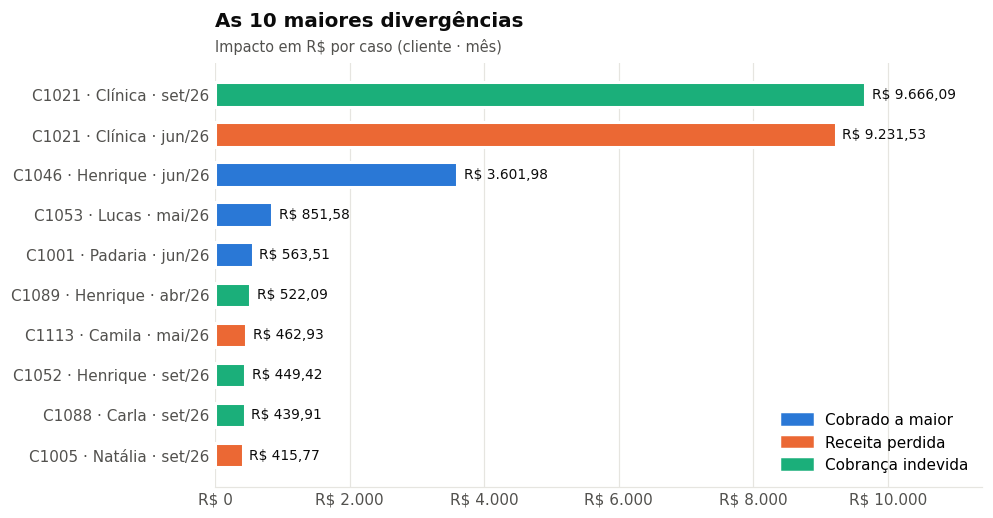

classificacao,id_cliente,nome,mes_referencia,valor_esperado,valor_cobrado,impacto,causa
Cobrança indevida,C1021,Clínica Vida Plena,2026-09,"R$ 0,00","R$ 9.666,09","R$ 9.666,09",Cliente cancelado em 08/07/2026; mês começa depois do cancelamento.
Fatura sem cobrança,C1021,Clínica Vida Plena,2026-06,"R$ 9.231,53",—,"R$ 9.231,53","Enel registrou energia compensada, mas a Goener não emitiu boleto."
Cobrado a maior,C1046,Henrique Barbosa Almeida,2026-06,"R$ 400,22","R$ 4.002,20","R$ 3.601,98",Vírgula deslocada: cobrado 10× o valor correto (erro de digitação)
Cobrado a maior,C1053,Lucas Araújo Pereira,2026-05,"R$ 94,62","R$ 946,20","R$ 851,58",Vírgula deslocada: cobrado 10× o valor correto (erro de digitação)
Cobrado a maior,C1001,Padaria Pão Dourado,2026-06,"R$ 2.721,89","R$ 3.285,40","R$ 563,51","Cobrança calculada sobre o consumo total, não sobre a energia compensada"
Cobrança indevida,C1089,Henrique Silva Holanda,2026-04,"R$ 0,00","R$ 522,09","R$ 522,09",Boleto duplicado: já existe outro boleto para o mesmo cliente e mês.
Fatura sem cobrança,C1113,Camila Araújo Sousa,2026-05,"R$ 462,93",—,"R$ 462,93","Enel registrou energia compensada, mas a Goener não emitiu boleto."
Cobrança indevida,C1052,Henrique Nogueira Mendes,2026-09,"R$ 0,00","R$ 449,42","R$ 449,42",Cliente cancelado em 14/07/2026; mês começa depois do cancelamento.
Cobrança indevida,C1088,Carla Costa Barbosa,2026-09,"R$ 0,00","R$ 439,91","R$ 439,91",Cliente cancelado em 24/06/2026; mês começa depois do cancelamento.
Fatura sem cobrança,C1005,Natália Barbosa Mendes,2026-09,"R$ 415,77",—,"R$ 415,77","Enel registrou energia compensada, mas a Goener não emitiu boleto."


In [18]:
top10 = indicadores.maiores_divergencias(conciliacao)
graficos.salvar_figura(graficos.grafico_maiores_divergencias(top10), "maiores_divergencias")
plt.show()
(top10.style.format({"valor_esperado": reais, "valor_cobrado": reais, "impacto": reais,
                     "mes_referencia": "{:%Y-%m}"}, na_rep="—").hide(axis="index"))

### 3.3 Qual a economia total gerada para os clientes? (prometida × recebida)

Economia recebida pelos clientes no período: R$ 111.209,15
Economia prometida no contrato (sem erros): R$ 117.267,76
Cobrado a mais dos clientes (a devolver): R$ 6.058,61


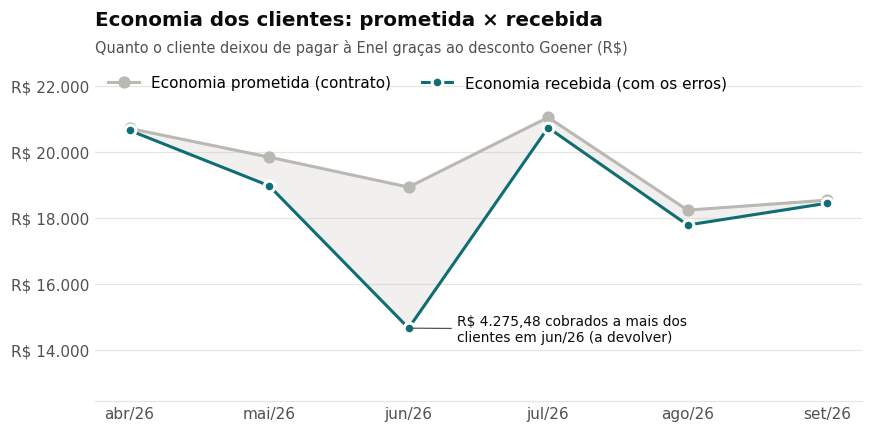

In [19]:
print(f"Economia recebida pelos clientes no período: {reais(resumo['economia_real'])}")
print(f"Economia prometida no contrato (sem erros): {reais(resumo['economia_contratada'])}")
print(f"Cobrado a mais dos clientes (a devolver): "
      f"{reais(resumo['economia_contratada'] - resumo['economia_real'])}")
graficos.salvar_figura(graficos.grafico_economia_mensal(mensal), "economia_mensal")
plt.show()

A Goener gerou **mais de R$ 111 mil de economia** para os clientes em 6 meses. Em **junho**, porém, **R$ 4,3 mil foram cobrados a mais** de 3 clientes (principalmente a vírgula deslocada do C1046). Esse valor não é lucro da Goener: precisa ser devolvido.

### 3.4 Qual o percentual de inadimplência?

Total vencido até 15/10/2026: R$ 656.502,76
Vencido e não pago: R$ 83.871,04
Inadimplência: 12.78%
(Se as cobranças indevidas entrassem na conta: 14.37%)


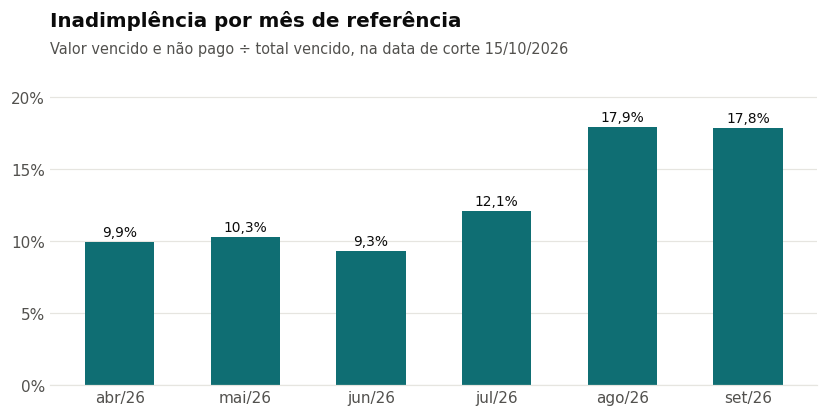

In [20]:
print(f"Total vencido até {cfg.DATA_CORTE:%d/%m/%Y}: {reais(resumo['total_vencido'])}")
print(f"Vencido e não pago: {reais(resumo['vencido_nao_pago'])}")
print(f"Inadimplência: {resumo['inadimplencia']:.2%}")
print(f"(Se as cobranças indevidas entrassem na conta: {resumo['inadimplencia_com_indevidas']:.2%})")
graficos.salvar_figura(graficos.grafico_inadimplencia_mensal(mensal), "inadimplencia_mensal")
plt.show()

A inadimplência **sobe nos meses mais recentes** (de ~10% para ~18%). Parte disso é natural, porque boletos que venceram há pouco tiveram menos tempo para serem pagos com atraso. Mesmo assim, a tendência merece acompanhamento. Se as cobranças indevidas fossem contadas, a taxa ficaria **inflada em 1,6 ponto** por um erro que é da Goener.

### 3.5 Como esses números evoluem mês a mês?

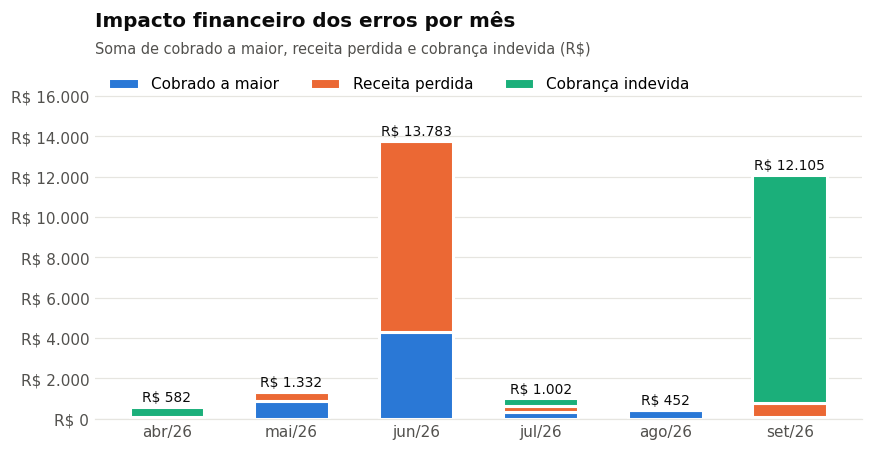

,valor_faturado,valor_a_maior,receita_perdida,valor_indevido,economia_real,inadimplencia,casos_com_erro
mes_referencia,,,,,,,
2026-04,"R$ 114.576,48","R$ 59,51","R$ 0,00","R$ 522,09","R$ 20.646,02",9.9%,2
2026-05,"R$ 110.746,76","R$ 869,11","R$ 462,93","R$ 0,00","R$ 18.967,21",10.3%,4
2026-06,"R$ 108.104,33","R$ 4.275,48","R$ 9.508,01","R$ 0,00","R$ 14.650,35",9.3%,5
2026-07,"R$ 117.157,26","R$ 310,04","R$ 337,15","R$ 354,82","R$ 20.730,48",12.1%,9
2026-08,"R$ 104.554,90","R$ 451,59","R$ 0,00","R$ 0,00","R$ 17.776,91",17.9%,2
2026-09,"R$ 101.363,03","R$ 92,88","R$ 670,73","R$ 11.341,06","R$ 18.438,18",17.8%,10


In [21]:
graficos.salvar_figura(graficos.grafico_impacto_mensal(mensal), "impacto_mensal")
plt.show()

(mensal[["valor_faturado", "valor_a_maior", "receita_perdida", "valor_indevido", "economia_real",
         "inadimplencia", "casos_com_erro"]]
 .rename(index=lambda m: f"{m:%Y-%m}")
 .style.format({c: reais for c in ["valor_faturado", "valor_a_maior", "receita_perdida",
                                   "valor_indevido", "economia_real"]} | {"inadimplencia": "{:.1%}"}))

- **Junho** foi o pior mês em valor: a receita perdida do C1021 somada à vírgula deslocada do C1046.
- **Setembro** concentra as **cobranças indevidas**: os 4 clientes cancelados receberam boleto, um sinal de que o processo de cancelamento **não está bloqueando a cobrança**.
- Os erros de valor (cobrado a maior) aparecem **todo mês**, ou seja, não é um evento isolado e sim um **problema de processo**.

### ✅ Conclusão da Etapa 3
O impacto total dos erros é de **~R$ 29 mil** (R$ 6 mil a maior + R$ 11 mil perdidos + R$ 12 mil indevidos) sobre R$ 656 mil faturados, ou **4,5%**. Os erros não são aleatórios: vêm de **4 falhas de processo** (desconto não aplicado, cálculo sobre consumo, digitação de valor e cancelamento que não bloqueia a cobrança). A Etapa 4 ataca exatamente esses pontos.

---
<h2 style="color:#0f6e73">Etapa 4 · Prevenção</h2>

**Objetivo:** corrigir uma vez não basta. O processo precisa **barrar** o erro antes que ele vire boleto.

O código (`src/validacao.py`) cria **duas barreiras**:

| Barreira | Quando atua | O que faz |
|---|---|---|
| **1. Contrato de dados** | Na chegada de qualquer arquivo novo | Confere cada aba contra regras de formato e de negócio e devolve **o que está fora do padrão**, com aba, linha, coluna, regra e valor |
| **2. Trava de emissão** | Antes de emitir os boletos do mês | Concilia o lote: só sai boleto **OK**. Os demais são bloqueados, e faturas sem boleto são apontadas |

Cada regra é uma função pequena. Para criar uma regra nova, basta escrever a função e incluí-la no contrato, sem mexer no resto do código.

### 4.1 Barreira 1: contrato de dados aplicado à base original
Se esse arquivo chegasse hoje, isto é o que a validação apontaria **antes** de qualquer processamento:

In [22]:
from src import validacao

violacoes_original = validacao.validar_arquivo(cfg.ARQUIVO_BASE)
print(f"{len(violacoes_original)} violações encontradas no arquivo original")
validacao.resumo_violacoes(violacoes_original)

2825 violações encontradas no arquivo original


,aba,coluna,regra,linhas_fora_do_padrao
0,clientes,id_cliente,único na base,8
1,clientes,nome,sem espaços nas pontas,16
2,clientes,cpf_cnpj,"11 (CPF) ou 14 (CNPJ) dígitos, sem pontuação",75
3,clientes,uc,10 dígitos com zeros à esquerda,40
4,clientes,uc,única entre clientes,8
5,clientes,desconto_contratado,obrigatório,2
6,clientes,desconto_contratado,fração com ponto decimal (ex.: 0.15),73
7,clientes,data_adesao,data AAAA-MM-DD,71
8,clientes,data_cancelamento,data AAAA-MM-DD,5
9,faturas_enel,uc,10 dígitos com zeros à esquerda,286


Cada linha do resultado aponta **exatamente** onde está o problema (linha do Excel), o que facilita devolver para quem enviou o arquivo:

In [23]:
violacoes_original.head(8)

,aba,linha,coluna,regra,valor
0,clientes,17,id_cliente,único na base,C1098
1,clientes,46,id_cliente,único na base,C1057
2,clientes,48,id_cliente,único na base,C1037
3,clientes,49,id_cliente,único na base,C1057
4,clientes,71,id_cliente,único na base,C1098
5,clientes,72,id_cliente,único na base,C1119
6,clientes,80,id_cliente,único na base,C1037
7,clientes,100,id_cliente,único na base,C1119


### 4.2 A base tratada passa no contrato?
Depois da Etapa 1, só devem sobrar os casos que **escolhemos** mandar para revisão humana (dado faltando ou contraditório). Tudo que era formato precisa ter sumido:

In [24]:
violacoes_tratada = pd.concat([
    validacao.validar_base(clientes.reset_index(drop=True), cfg.ABA_CLIENTES),
    validacao.validar_base(faturas.reset_index(drop=True), cfg.ABA_FATURAS),
    validacao.validar_base(cobrancas.reset_index(drop=True), cfg.ABA_COBRANCAS),
    validacao.validar_relacionamentos(clientes, faturas, cobrancas),
], ignore_index=True)
print(f"Antes: {len(violacoes_original)} violações  →  Depois: {len(violacoes_tratada)}")
validacao.resumo_violacoes(violacoes_tratada)

Antes: 2825 violações  →  Depois: 25


,aba,coluna,regra,linhas_fora_do_padrao
0,clientes,desconto_contratado,obrigatório,2
1,faturas_enel,energia_compensada_kwh,obrigatória,5
2,faturas_enel,energia_compensada_kwh,não pode ser maior que o consumo,4
3,cobrancas_goener,data_pagamento,obrigatória quando status é pago,3
4,cobrancas_goener,id_cliente,um boleto por cliente e mês,8
5,faturas_enel,uc,UC precisa existir no cadastro de clientes,3


✅ Não sobrou nenhum erro de **formato**. O que resta é exatamente a lista de **revisão humana** da Etapa 1 (desconto vazio, energia compensada vazia ou maior que o consumo, "pago" sem data, boletos duplicados e UCs sem cadastro). Isso confirma que o tratamento e a validação concordam entre si.

> Por que 25 violações e 21 registros em revisão? O contrato acusa **os dois boletos** de cada um dos 4 pares duplicados (8 linhas), enquanto o log manda para revisão só o boleto **extra** de cada par (4). O resto é igual: 2 + 5 + 4 + 3 + 3.

### 4.3 Barreira 2: trava antes da emissão dos boletos
Simulação: se o lote de boletos deste período passasse pela trava **antes** de ser enviado aos clientes:

In [25]:
aprovados, bloqueados, faltantes = validacao.validar_lote_cobranca(clientes, faturas, cobrancas)

display(pd.DataFrame({"boletos": [len(aprovados), len(bloqueados), len(faltantes)],
                      "valor": [reais(aprovados.valor_cobrado.sum()), reais(bloqueados.valor_cobrado.sum()),
                                reais(faltantes.valor_esperado.sum())]},
                     index=["✅ aprovados para emissão", "⛔ bloqueados para revisão", "➕ faturas sem boleto (gerar)"]))
bloqueados.groupby("classificacao", observed=True).size().rename("bloqueados por motivo").to_frame()

,boletos,valor
✅ aprovados para emissão,666,"R$ 628.723,99"
⛔ bloqueados para revisão,43,"R$ 39.996,74"
➕ faturas sem boleto (gerar),6,"R$ 10.978,82"


,bloqueados por motivo
classificacao,
Cobrado a maior,15
Cobrança indevida,8
Inconclusivo,20


Com a trava, **nenhum** dos boletos errados teria chegado ao cliente: as 15 cobranças a maior, as 8 indevidas e os inconclusivos ficariam retidos. As 6 faturas sem boleto seriam apontadas **antes** do fechamento do mês, em vez de virarem receita perdida.

### 4.4 Testes automáticos
Os testes (`tests/`) provam que cada validação funciona. Eles usam **dados pequenos e controlados**, com um caso para cada erro encontrado no case, e um teste de ponta a ponta com o arquivo real:

| Arquivo | O que garante |
|---|---|
| `test_normalizacao.py` | Cada formato da base (UC, CPF, desconto, R$, datas, mês) é convertido corretamente |
| `test_validacao.py` | O contrato aceita uma base correta e acusa cada tipo de erro |
| `test_conciliacao.py` | Regra do enunciado, tolerância de R$ 0,05, cada classificação e a trava de emissão |
| `test_sql.py` | As consultas SQL chegam aos mesmos resultados do Python |
| `test_pipeline.py` | O processo completo roda no arquivo real sem perder faturas nem boletos |

In [26]:
import subprocess

execucao = subprocess.run([sys.executable, "-m", "pytest", "-q", "--no-header", "--color=no", "-p", "no:cacheprovider", "tests"],
                          cwd=RAIZ, capture_output=True, text=True)
print(execucao.stdout[-600:])

........................................................................ [ 96%]
...                                                                      [100%]
75 passed in 3.04s



### 4.5 Como eu colocaria isso em produção

**Quando rodaria**
- **Na chegada de cada arquivo** (exportação da Enel, cadastro comercial, sistema de cobrança): a Barreira 1 roda automaticamente e o arquivo só entra se passar no contrato.
- **Antes do lote mensal de emissão** (alguns dias antes do vencimento do dia 10): a Barreira 2 roda sobre os boletos propostos. **Nenhum boleto é emitido sem passar pela trava.**
- **Diariamente**, uma conciliação completa atualiza os indicadores e o dashboard.

**Quem seria avisado**
| Situação | Quem recebe | Por quê |
|---|---|---|
| Boleto bloqueado por valor ou duplicidade | **Financeiro** | É quem corrige e emite |
| Desconto vazio, UC sem cadastro, cancelamento | **Comercial / CS** | É dono do cadastro e do contrato |
| Energia compensada vazia ou maior que o consumo | **Operações** | Consulta a fatura na Enel |
| Arquivo com erro em massa (ex.: formato mudou) | **Tecnologia** | Indica problema na integração, não no dado |
| Resumo semanal de impacto e inadimplência | **Gestão** | Acompanha a tendência |

O aviso vai por e-mail ou Teams com a lista de pendências e o link do dashboard.

**O que acontece com um registro rejeitado**
1. **Não é apagado.** Vai para uma tabela de **quarentena** com o motivo, a linha de origem, o responsável e um prazo (ex.: 2 dias úteis).
2. **Não segue** para a conciliação nem para a emissão. Os outros registros seguem normalmente, então um erro isolado não trava o mês inteiro.
3. Corrigido **na origem** (cadastro ou sistema), o registro é **reprocessado automaticamente** na próxima execução.
4. Se a proporção de rejeitados passar de um limite (ex.: 5% do arquivo), o **arquivo inteiro** é parado: é sinal de problema na integração.
5. Tudo fica registrado no log, com histórico para auditoria.

**Corrigir a causa, não só o sintoma.** As validações seguram o erro, mas as 4 falhas de processo da Etapa 3 pedem mudanças no sistema de cobrança:
- **o valor do boleto nunca é digitado**: é sempre calculado pela regra (acaba a vírgula deslocada);
- **o desconto vem do cadastro**, como campo obrigatório (acaba o "desconto não aplicado");
- **a base de cálculo é a energia compensada**, não o consumo;
- **o cancelamento bloqueia a emissão automaticamente** a partir do mês seguinte.

### ✅ Conclusão da Etapa 4
O arquivo original teria sido **barrado na entrada** com cada problema apontado por linha. A base tratada passa no contrato, e o que sobra são só casos de revisão humana. A trava de emissão teria impedido **todos** os boletos errados de chegar ao cliente, e **75 testes automáticos** garantem que essas regras continuam funcionando a cada mudança no código.

---
<h2 style="color:#0f6e73">Diferenciais</h2>

### D1 · SQL como conferência independente
As consultas em `sql/consultas.sql` **recalculam com SQL**, direto das tabelas tratadas, o que o Python calculou. Se as duas linguagens chegam ao mesmo número, a lógica está conferida. Os parâmetros (tolerância e data de corte) vêm do `config.py` e não ficam fixos no SQL.

In [27]:
from src import consultas_sql

banco = consultas_sql.criar_banco({"clientes": clientes, "faturas": faturas,
                                   "cobrancas": cobrancas, "conciliacao": conciliacao})
print(consultas_sql.carregar_consultas()["cobrancas_apos_cancelamento"])
consultas_sql.executar(banco, "cobrancas_apos_cancelamento")

-- Regra: cliente cancelado não pode ser cobrado por mês que começa depois do cancelamento.
SELECT b.id_cobranca, b.id_cliente, c.nome, c.data_cancelamento, b.mes_referencia, b.valor_cobrado,
       b.status_pagamento
FROM cobrancas AS b
JOIN clientes  AS c ON c.id_cliente = b.id_cliente
WHERE c.status = 'cancelado'
  AND b.mes_referencia > c.data_cancelamento
ORDER BY b.valor_cobrado DESC;


,id_cobranca,id_cliente,nome,data_cancelamento,mes_referencia,valor_cobrado,status_pagamento
0,GB50713,C1021,Clínica Vida Plena,2026-07-08,2026-09-01,9666.09,em aberto
1,GB50714,C1052,Henrique Nogueira Mendes,2026-07-14,2026-09-01,449.42,em aberto
2,GB50715,C1088,Carla Costa Barbosa,2026-06-24,2026-09-01,439.91,em aberto
3,GB50712,C1040,Henrique Cavalcante Bezerra,2026-07-14,2026-09-01,194.27,em aberto


In [28]:
# Conferência: SQL × Python
sql_divergencias = consultas_sql.executar(banco, "divergencias_de_valor")
sql_inadimplencia = consultas_sql.executar(banco, "inadimplencia_total").iloc[0]
sql_receita = consultas_sql.executar(banco, "faturas_sem_cobranca")

conferencia = pd.DataFrame({
    "SQL": [len(sql_divergencias), reais(sql_receita.receita_perdida.sum()), f"{sql_inadimplencia.inadimplencia:.2%}"],
    "Python": [len(errados), reais(resumo["receita_perdida"]), f"{resumo['inadimplencia']:.2%}"],
}, index=["boletos com valor errado", "receita perdida", "inadimplência"])
conferencia["bate?"] = (conferencia.SQL == conferencia.Python).map({True: "✅", False: "❌"})
conferencia

,SQL,Python,bate?
boletos com valor errado,15,15,✅
receita perdida,"R$ 10.978,82","R$ 10.978,82",✅
inadimplência,12.78%,12.78%,✅


### D2 · Dashboard no Power BI
As tabelas em `output/powerbi/` estão no formato **estrela**: a `fato_conciliacao` fica no centro, ligada a `dim_clientes` e `dim_calendario`. O guia **`docs/GUIA_POWERBI.md`** traz o passo a passo: importação (com o cuidado de localidade para o ponto decimal), relacionamentos, **medidas DAX prontas** e o layout das 4 páginas.

A tabela de calendário é gerada a partir do período das bases:

In [29]:
from src.exportacao import criar_calendario

dim_calendario = criar_calendario(faturas.mes_referencia)
dim_calendario

,mes_referencia,ano,mes,mes_nome,mes_ano,trimestre
0,2026-04-01,2026,4,abr,abr/26,T2
1,2026-05-01,2026,5,mai,mai/26,T2
2,2026-06-01,2026,6,jun,jun/26,T2
3,2026-07-01,2026,7,jul,jul/26,T3
4,2026-08-01,2026,8,ago,ago/26,T3
5,2026-09-01,2026,9,set,set/26,T3


### D3 · Proposta no Microsoft Fabric
Detalhada em **`docs/PROPOSTA_FABRIC.md`** (com diagrama). Em resumo, o **mesmo código** de `src/` roda no Fabric em camadas:

```
 Enel / CRM / Cobrança
          │  Data Factory (na chegada do arquivo)
          ▼
   BRONZE  arquivo como chegou ─────────────────────┐
          │  Notebook: contrato de dados + limpeza    │ fora do contrato
          ▼                                           ▼
   SILVER  tabelas tratadas + log            QUARENTENA ──► Activator ──► Teams/e-mail
          │  Notebook: conciliação + indicadores      ▲        (Financeiro, Comercial,
          ▼                                           │         Operações, Gestão)
   GOLD    conciliação + KPIs ──► Power BI (Direct Lake)
          │
          ▼  antes da emissão mensal
   TRAVA   só boletos OK ──► sistema de cobrança     bloqueados ──┘
```

- **Gatilhos:** chegada de arquivo, rotina diária e antes do lote mensal de emissão.
- **Qualidade de software:** Git integrado, ambientes dev/teste/produção e os testes `pytest` rodando antes de cada implantação.
- **LGPD:** CPF/CNPJ mascarado na camada Gold e no Power BI.
- **Alternativa:** a mesma lógica como **API em Go** (`POST /v1/lotes-cobranca/validar`), chamada pelo sistema de cobrança antes de emitir.

---
<h2 style="color:#0f6e73">Resumo executivo</h2>

Texto para um gestor **não técnico**: o que foi encontrado, quanto custa e o que recomendo. Também é gerado em PDF de 1 página (`output/resumo_executivo.pdf`).

Os números são **calculados pela análise** (`src/resumo_executivo.py`), não digitados: se a base mudar, o resumo se atualiza junto.

In [30]:
from src import resumo_executivo

conteudo_resumo = resumo_executivo.montar_conteudo(resumo, conciliacao, mensal, log, violacoes_original)
display(HTML(resumo_executivo.gerar_html(conteudo_resumo)))

---
## Salvando os resultados
- `output/base_tratada.xlsx`: conciliação, indicadores mensais, bases limpas, log completo, resumo do log e violações do contrato na base original (entregável 2)
- `output/powerbi/*.csv`: tabelas no formato estrela, prontas para o Power BI
- `output/graficos/*.png`: gráficos da Etapa 3 (para o resumo executivo e a apresentação)
- `output/resumo_executivo.pdf`: resumo executivo de 1 página (entregável 3)
- `ERROS_E_LOGS.md`: documentação de todos os erros (dados e cobranças), gerada a partir do log

In [31]:
indicadores_mensais = mensal.reset_index()
salvar_excel({
    "conciliacao": conciliacao, "indicadores_mensais": indicadores_mensais,
    "clientes": clientes, "faturas_enel": faturas,
    "cobrancas_goener": cobrancas, "log_inconsistencias": df_log, "resumo_log": log.resumo(),
    "validacao_base_original": violacoes_original,
}, cfg.PASTA_SAIDA / "base_tratada.xlsx")
salvar_csv_powerbi({"fato_conciliacao": conciliacao, "indicadores_mensais": indicadores_mensais,
                    "dim_clientes": clientes, "dim_calendario": dim_calendario, "fato_faturas": faturas,
                    "fato_cobrancas": cobrancas, "log_inconsistencias": df_log})
gerar_markdown(log, brutas, resultado, conciliacao)
resumo_executivo.gerar_pdf(conteudo_resumo, cfg.PASTA_SAIDA / "resumo_executivo.pdf",
                           grafico=cfg.PASTA_SAIDA / "graficos" / "impacto_mensal.png")
print("Arquivos gerados em", cfg.PASTA_SAIDA.relative_to(RAIZ), "e", cfg.ARQUIVO_MARKDOWN_ERROS.name)

Arquivos gerados em output e ERROS_E_LOGS.md
